# MS6 — Clustering géospatial des élèves de Meknès
### Étude Data Science complète (démarche CRISP-DM)

**PFE Master SDIA — Plateforme intelligente de transport scolaire**
Étudiant : Anass Zbir · Encadrant : Pr. Ali Bekri · FS Meknès — 2025/2026

---

Ce notebook constitue le **volet data science** du microservice de clustering (MS6). Il applique
une démarche rigoureuse et reproductible pour regrouper **300 élèves** de Meknès en **groupes de
ramassage** réalisables pour un bus, puis sélectionne l'algorithme optimal par une **évaluation
multi-critères**.

**Démarche CRISP-DM :**
1. *Business Understanding* — objectif métier et contraintes
2. *Data Understanding* — analyse exploratoire (EDA)
3. *Data Preparation* — projection géographique correcte
4. *Modeling* — 5 algorithmes de clustering
5. *Evaluation* — indices internes, KPI métier, stabilité
6. *Deployment* — gel du modèle pour MS6

> **Reproductibilité.** Le notebook lit un instantané figé (`data/eleves_meknes.csv`, graine 42).
> Les dépendances avancées (pyproj, k-means-constrained, kneed, folium) sont **optionnelles** :
> en leur absence, des solutions de repli équivalentes sont utilisées automatiquement.

## 0. Environnement et configuration

**🔎 Approche.** On importe les bibliothèques (numpy, pandas, matplotlib, scikit-learn) et on active les modules optionnels (pyproj, k-means-constrained, kneed, folium, HDBSCAN) avec un repli automatique s'ils sont absents.

In [1]:
import math
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")
np.set_printoptions(suppress=True)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (8, 6)

# --- Imports optionnels avec repli gracieux ---------------------------------
def _try(name):
    try:
        return __import__(name), True
    except Exception:
        return None, False

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="deep")
    HAS_SNS = True
except Exception:
    HAS_SNS = False

try:
    from pyproj import Transformer
    HAS_PYPROJ = True
except Exception:
    HAS_PYPROJ = False

try:
    from k_means_constrained import KMeansConstrained
    HAS_KMC = True
except Exception:
    HAS_KMC = False

try:
    from kneed import KneeLocator
    HAS_KNEED = True
except Exception:
    HAS_KNEED = False

try:
    import folium
    HAS_FOLIUM = True
except Exception:
    HAS_FOLIUM = False

# HDBSCAN : présent nativement dans scikit-learn >= 1.3
try:
    from sklearn.cluster import HDBSCAN
    HAS_HDBSCAN = True
except Exception:
    HAS_HDBSCAN = False

import sklearn
print("Bibliothèques principales : numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("Optionnels  ->  seaborn:", HAS_SNS, "| pyproj:", HAS_PYPROJ,
      "| k-means-constrained:", HAS_KMC, "| kneed:", HAS_KNEED,
      "| folium:", HAS_FOLIUM, "| HDBSCAN(sklearn):", HAS_HDBSCAN)

Bibliothèques principales : numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.5.0
Optionnels  ->  seaborn: True | pyproj: True | k-means-constrained: True | kneed: True | folium: True | HDBSCAN(sklearn): True


**Paramètres métier.** La flotte de bus est un *exemple de simulation extensible* : la
capacité est donc un **paramètre**, et le nombre de groupes est **dérivé** de la demande
(`k = ⌈N / capacité⌉`) plutôt que fixé arbitrairement.

**🔎 Approche.** On fixe les paramètres **métier** : capacité d'un bus, seuil de qualité Silhouette (0.5) et le système de projection géographique (UTM 30N). La capacité est un simple paramètre, modifiable à volonté.

In [2]:
# ----- Paramètres métier (modifiables) --------------------------------------
BUS_CAPACITY = 50          # capacité par bus (sièges) — paramètre extensible
MIN_SILHOUETTE = 0.50      # garde-fou qualité (CDC §4.3.2) : pas d'application si <= 0.5
EPSG_METRIC = 32630        # UTM zone 30N (Meknès) pour la projection planaire

DATA_PATH = Path("../data/eleves_meknes.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=130, bbox_inches="tight")


## 1. Compréhension métier (*Business Understanding*)

**Problème.** Affecter ~300 élèves à des **groupes de ramassage** desservis chacun par un bus.

**Objectifs (et leur traduction mesurable) :**

| Objectif métier | Métrique data science |
|---|---|
| Groupes compacts (peu de marche / détours) | distance intra-groupe (moyenne & max, en **mètres**) |
| Groupes réalisables pour un bus | **faisabilité capacité** : taille ≤ capacité |
| Groupes équilibrés (remplissage homogène) | coefficient de variation (CV) des tailles |
| Séparation nette des groupes | **Silhouette**, Davies-Bouldin, Calinski-Harabasz |
| Robustesse à l'évolution (déclencheurs S8) | **stabilité** (ARI entre exécutions / bootstrap) |

**Contraintes (CDC).**
- `GroupeEleves → 1 Bus` : un groupe est affecté à **un** bus ⇒ **taille ≤ capacité**.
- Garde-fou qualité : **Silhouette > 0.5** requis pour valider une configuration.
- Validation administrateur obligatoire avant application (gérée côté MS6).

## 2. Compréhension des données (*EDA*)

Instantané reproductible (graine 42), généré par un modèle **réaliste** de Meknès :
- une **destination commune** : l'établissement scolaire (les bus convergent vers lui) ;
- une structure **multi-échelle** : *zones* résidentielles → *secteurs* denses (lotissements,
  résidences), séparées par le corridor de l'**oued Boufekrane** et des coupures péri-urbaines ;
- ~5 % d'élèves **dispersés** (péri-urbain) → vrais points aberrants pour les méthodes de densité.

Seules les coordonnées GPS du domicile servent à entraîner les modèles. Les colonnes `quartier`,
`zone`, `secteur` sont des **vérités terrain** (multi-niveau) réservées à la validation externe
(ARI/AMI) ; `distance_ecole_m` est un descripteur métier exploité en EDA.

**🔎 Approche.** On charge l'instantané figé des 300 élèves (graine 42) : l'étude est ainsi 100 % reproductible, sans dépendre des microservices.

In [3]:
df = pd.read_csv(DATA_PATH)
print("Dimensions :", df.shape)
df.head()

Dimensions : (300, 13)


,id,nom,prenom,latitude,longitude,quartier,zone,secteur,niveau,ecole_nom,ecole_lat,ecole_lng,distance_ecole_m
0,1,Bennouna,Youssef,33.890502,-5.551733,Sidi Baba,Hamria-Centre,Sidi Baba,Collège,Groupe Scolaire Al Massira — Meknès,33.893,-5.5455,638.8
1,2,Benomar,Bilal,33.897403,-5.564345,Medina,Medina-Ouest,Médina Nord,Collège,Groupe Scolaire Al Massira — Meknès,33.893,-5.5455,1806.9
2,3,Kasmi,Ahmed,33.889270,-5.570806,Dispersé,Périurbain,Dispersé,Primaire,Groupe Scolaire Al Massira — Meknès,33.893,-5.5455,2372.4
3,4,Benbrahim,Othmane,33.894175,-5.566880,Medina,Medina-Ouest,Médina Sud,Primaire,Groupe Scolaire Al Massira — Meknès,33.893,-5.5455,1977.7
4,5,Berrada,Nora,33.876687,-5.526447,Nouzhat,SudEst-AinKarma,Nouzhat,Primaire,Groupe Scolaire Al Massira — Meknès,33.893,-5.5455,2526.6


**🔎 Approche.** Contrôle qualité de base avant de modéliser : types des colonnes, valeurs manquantes et doublons de coordonnées.

In [4]:
# Qualité des données : types, valeurs manquantes, doublons
print(df.dtypes, "\n")
print("Valeurs manquantes :\n", df.isna().sum(), "\n")
print("Doublons (lat,lon) :", df.duplicated(subset=["latitude", "longitude"]).sum())
df[["latitude", "longitude"]].describe()

id                    int64
nom                     str
prenom                  str
latitude            float64
longitude           float64
quartier                str
zone                    str
secteur                 str
niveau                  str
ecole_nom               str
ecole_lat           float64
ecole_lng           float64
distance_ecole_m    float64
dtype: object 

Valeurs manquantes :
 id                  0
nom                 0
prenom              0
latitude            0
longitude           0
quartier            0
zone                0
secteur             0
niveau              0
ecole_nom           0
ecole_lat           0
ecole_lng           0
distance_ecole_m    0
dtype: int64 

Doublons (lat,lon) : 0


,latitude,longitude
count,300.000000,300.000000
mean,33.886235,-5.545280
std,0.012332,0.012733
min,33.867625,-5.571515
25%,33.875852,-5.554891
50%,33.884608,-5.545697
75%,33.897304,-5.535241
max,33.908694,-5.523576


**🔎 Approche.** On compte les élèves par quartier (la **vérité terrain**) pour comprendre comment la population est répartie sur la ville.

Nombre de quartiers : 16


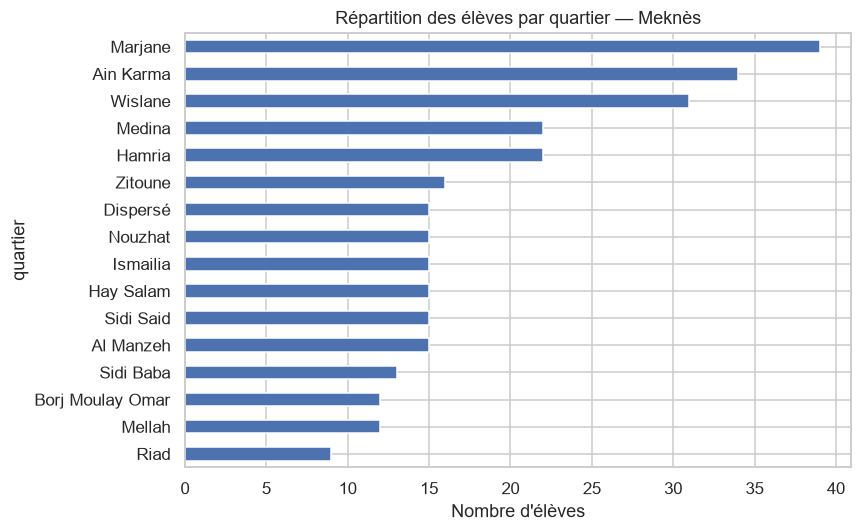

In [5]:
# Répartition par quartier (vérité terrain)
counts = df["quartier"].value_counts()
print("Nombre de quartiers :", df["quartier"].nunique())
ax = counts.plot(kind="barh", color="#4C72B0", figsize=(8, 5))
ax.invert_yaxis(); ax.set_xlabel("Nombre d'élèves"); ax.set_title("Répartition des élèves par quartier — Meknès")
savefig("01_repartition_quartiers.png"); plt.show()

**🔎 Approche.** On place chaque élève sur un plan longitude/latitude, coloré par quartier, pour visualiser la géographie réelle du problème.

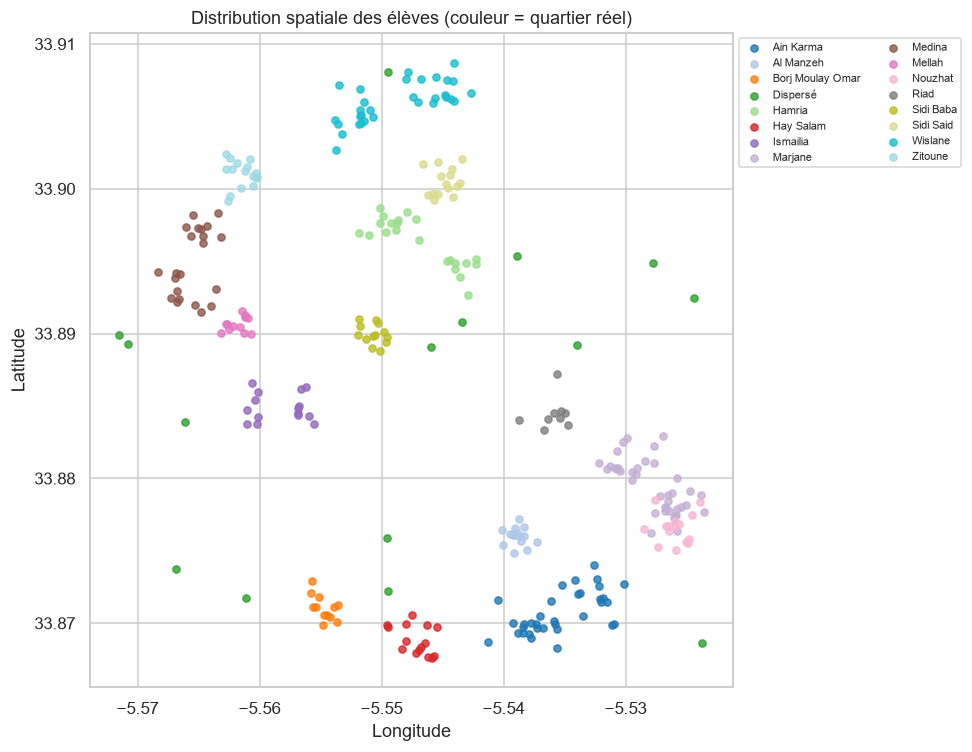

In [6]:
# Distribution spatiale colorée par quartier
quartiers = sorted(df["quartier"].unique())
cmap = colormaps["tab20"].resampled(len(quartiers))
colors = {q: cmap(i) for i, q in enumerate(quartiers)}
plt.figure(figsize=(9, 7))
for q in quartiers:
    sub = df[df["quartier"] == q]
    plt.scatter(sub["longitude"], sub["latitude"], s=22, color=colors[q], label=q, alpha=0.8)
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Distribution spatiale des élèves (couleur = quartier réel)")
plt.legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(1.0, 1.0))
savefig("02_distribution_spatiale.png"); plt.show()

### L'établissement scolaire et la distance domicile → école
La destination commune structure le problème : les bus partent des poches résidentielles et
convergent vers l'école. La distribution des distances domicile→école éclaire l'effort de
ramassage et servira plus tard à l'ETA et au VRP.

**🔎 Approche.** On situe l'**établissement scolaire** (destination, étoile rouge) et le **corridor de l'oued** qui sépare naturellement la médina de la ville nouvelle — deux éléments structurants du problème.

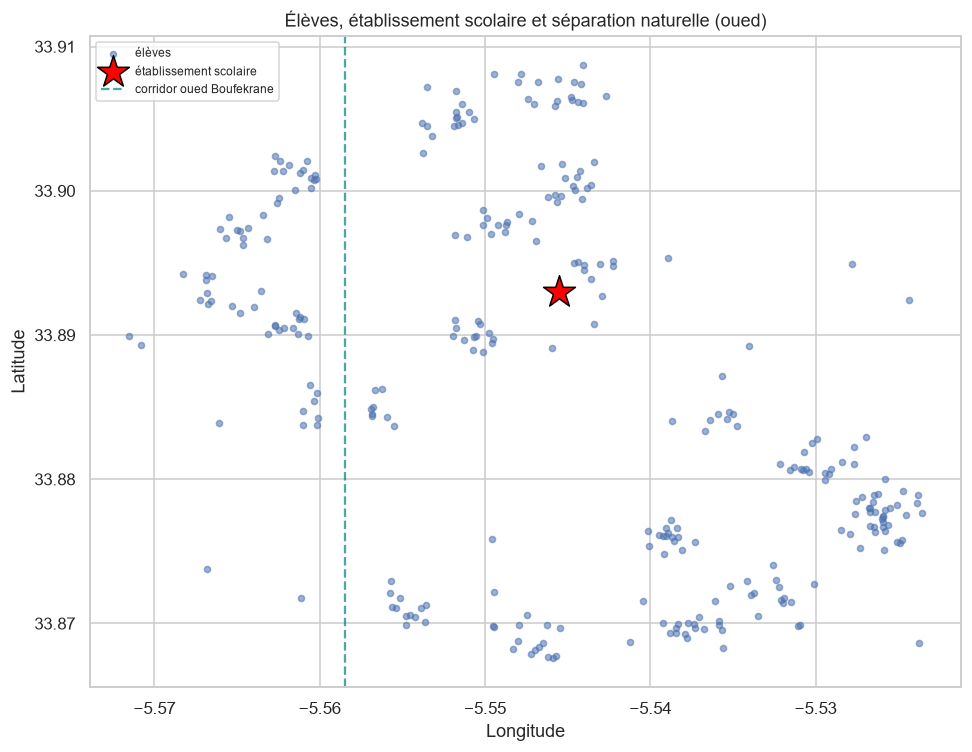

In [7]:
# Carte : élèves + établissement scolaire (destination) + corridor de l'oued
ECOLE_LAT, ECOLE_LNG = df["ecole_lat"].iloc[0], df["ecole_lng"].iloc[0]
OUED_LON = -5.5585
plt.figure(figsize=(9, 7))
plt.scatter(df["longitude"], df["latitude"], s=16, c="#4C72B0", alpha=0.55, label="élèves")
plt.scatter([ECOLE_LNG], [ECOLE_LAT], marker="*", s=480, c="red",
            edgecolor="black", zorder=5, label="établissement scolaire")
plt.axvline(OUED_LON, color="teal", ls="--", lw=1.5, alpha=0.7, label="corridor oued Boufekrane")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Élèves, établissement scolaire et séparation naturelle (oued)")
plt.legend(loc="upper left", fontsize=8)
savefig("02b_ecole_oued.png"); plt.show()

**🔎 Approche.** Histogramme des **distances domicile → école** : il quantifie l'effort de ramassage et servira plus tard à l'ETA (prédiction d'arrivée) et au VRP (optimisation des tournées).

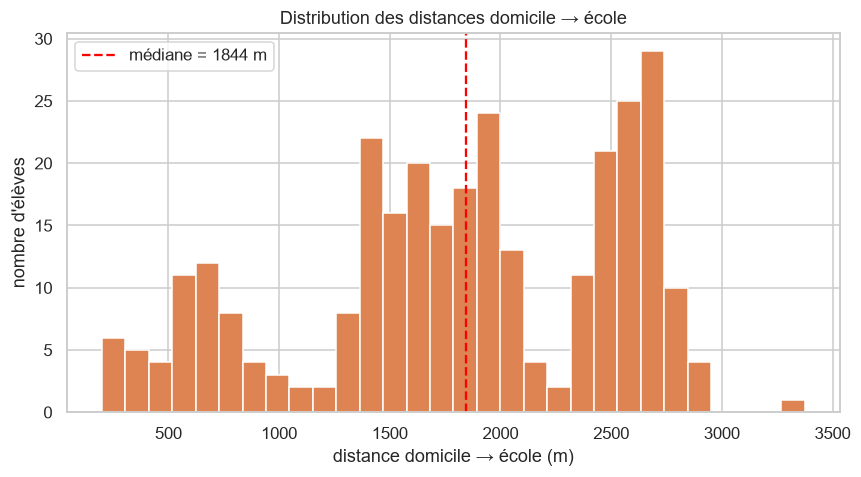

Distance école : médiane=1844 m | moyenne=1815 m | max=3375 m


In [8]:
# Distance domicile -> école (descripteur métier)
d = df["distance_ecole_m"]
plt.figure(figsize=(8, 4.5))
plt.hist(d, bins=30, color="#DD8452", edgecolor="white")
plt.axvline(d.median(), color="red", ls="--", label=f"médiane = {d.median():.0f} m")
plt.xlabel("distance domicile → école (m)"); plt.ylabel("nombre d'élèves")
plt.title("Distribution des distances domicile → école")
plt.legend(); savefig("02c_distance_ecole.png"); plt.show()
print(f"Distance école : médiane={d.median():.0f} m | moyenne={d.mean():.0f} m | max={d.max():.0f} m")

**🔎 Approche.** On observe la **densité** : les cases foncées (hexbin) indiquent les zones où beaucoup d'élèves habitent.

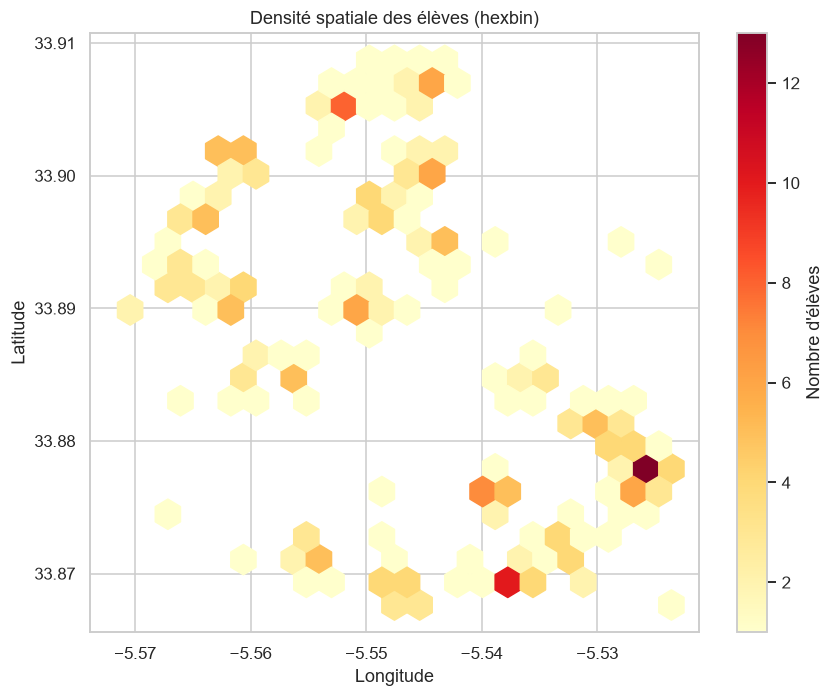

In [9]:
# Densité spatiale (hexbin) — révèle les zones de concentration
plt.figure(figsize=(8, 6.5))
hb = plt.hexbin(df["longitude"], df["latitude"], gridsize=22, cmap="YlOrRd", mincnt=1)
plt.colorbar(hb, label="Nombre d'élèves")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title("Densité spatiale des élèves (hexbin)")
savefig("03_densite_hexbin.png"); plt.show()

**🔎 Approche.** Version lissée de la densité (courbes de niveau KDE) : elle révèle de façon continue les pôles de concentration des élèves.

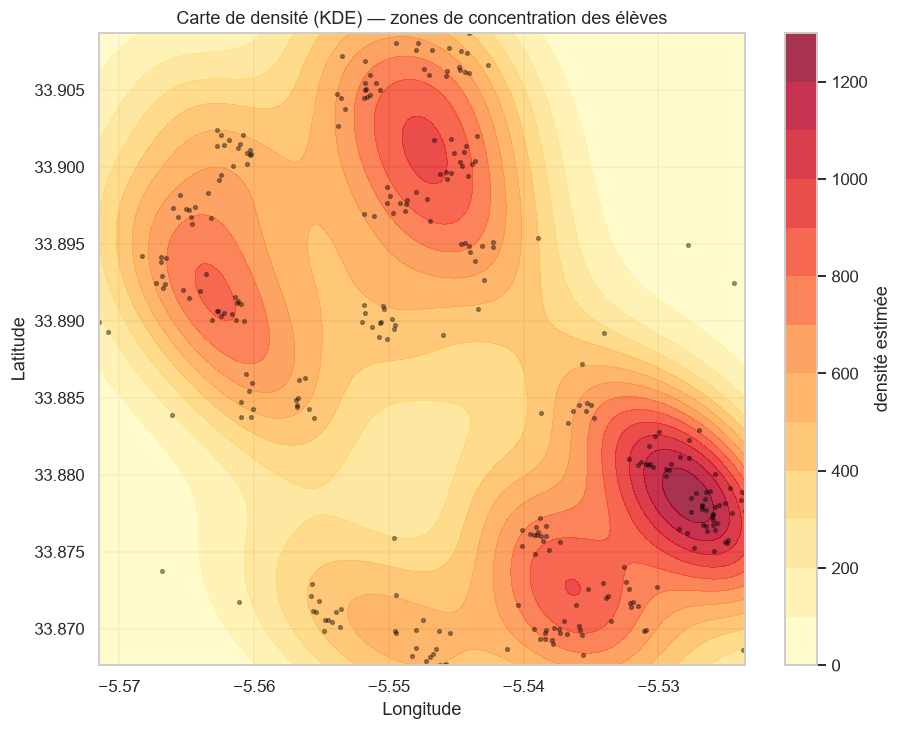

In [10]:
# Carte de densité par estimation de noyau (KDE) — surfaces de concentration continues
from scipy.stats import gaussian_kde
xy_kde = np.vstack([df["longitude"], df["latitude"]])
kde = gaussian_kde(xy_kde)
xx, yy = np.meshgrid(
    np.linspace(df["longitude"].min(), df["longitude"].max(), 160),
    np.linspace(df["latitude"].min(), df["latitude"].max(), 160))
zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
plt.figure(figsize=(8.5, 6.8))
cf = plt.contourf(xx, yy, zz, levels=12, cmap="YlOrRd", alpha=0.8)
plt.colorbar(cf, label="densité estimée")
plt.scatter(df["longitude"], df["latitude"], s=6, c="black", alpha=0.35)
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Carte de densité (KDE) — zones de concentration des élèves")
savefig("03b_densite_kde.png"); plt.show()

**🔎 Approche.** Carte **interactive** (fond OpenStreetMap) pour explorer les élèves, quartier par quartier, directement dans le navigateur.

In [11]:
# Carte interactive (optionnelle, folium)
if HAS_FOLIUM:
    import folium
    centre = [df["latitude"].mean(), df["longitude"].mean()]
    m = folium.Map(location=centre, zoom_start=13, tiles="OpenStreetMap")
    for q in quartiers:
        c = colors[q]; hexc = "#%02x%02x%02x" % (int(c[0]*255), int(c[1]*255), int(c[2]*255))
        for _, r in df[df["quartier"] == q].iterrows():
            folium.CircleMarker([r["latitude"], r["longitude"]], radius=3,
                                color=hexc, fill=True, fill_opacity=0.8,
                                popup=f"{r['prenom']} {r['nom']} ({q})").add_to(m)
    m.save(str(FIG_DIR / "carte_eleves.html"))
    print("Carte enregistrée -> figures/carte_eleves.html")
    display(m)
else:
    print("folium non installé — carte interactive ignorée (scatter matplotlib ci-dessus).")

Carte enregistrée -> figures/carte_eleves.html


## 3. Préparation des données — rigueur géographique

### Pourquoi pas `StandardScaler(lat, lon)` ?
À Meknès (latitude ≈ 33.9°), **1° de longitude ≈ 0.83° de latitude** en distance réelle
(facteur `cos(lat)`). `StandardScaler` ramène lat et lon à une variance unitaire et **détruit ce
rapport d'aspect** : les « distances » manipulées par K-Means ne correspondent plus aux distances
au sol. C'est l'erreur méthodologique de l'implémentation initiale.

### Solution : projection planaire locale (mètres)
On projette en **UTM 30N (EPSG:32630)** via `pyproj` (ou un plan tangent local équivalent si pyproj
est absent). En mètres, la **distance euclidienne = distance terrain**, et la Silhouette
s'interprète directement en mètres.

**🔎 Approche.** Étape clé : on convertit les degrés (lat/lon) en **mètres** (projection UTM). En mètres, la distance euclidienne = vraie distance au sol — indispensable pour un clustering géographiquement correct.

In [12]:
def to_meters(lat, lon):
    """Projette (lat, lon) -> (x, y) en mètres. UTM 30N si pyproj dispo, sinon plan tangent local."""
    lat = np.asarray(lat, float); lon = np.asarray(lon, float)
    if HAS_PYPROJ:
        tr = Transformer.from_crs("EPSG:4326", f"EPSG:{EPSG_METRIC}", always_xy=True)
        x, y = tr.transform(lon, lat)
        return np.column_stack([x, y]), "UTM 30N (EPSG:32630, pyproj)"
    # Repli : plan tangent local (équidistant azimutal local), exact à l'échelle d'une ville
    lat0, lon0 = lat.mean(), lon.mean()
    x = np.radians(lon - lon0) * 6371000.0 * math.cos(math.radians(lat0))
    y = np.radians(lat - lat0) * 6371000.0
    return np.column_stack([x, y]), "Plan tangent local (repli sans pyproj)"

XY, proj_name = to_meters(df["latitude"].values, df["longitude"].values)
df["x_m"], df["y_m"] = XY[:, 0], XY[:, 1]
print("Projection utilisée :", proj_name)
print(f"Emprise : {np.ptp(XY[:,0]):.0f} m (E-O) x {np.ptp(XY[:,1]):.0f} m (N-S)")
df[["latitude", "longitude", "x_m", "y_m"]].head()

Projection utilisée : UTM 30N (EPSG:32630, pyproj)
Emprise : 4401 m (E-O) x 4551 m (N-S)


,latitude,longitude,x_m,y_m
0,33.890502,-5.551733,264021.325252,3.752946e+06
1,33.897403,-5.564345,262873.816591,3.753741e+06
2,33.889270,-5.570806,262253.625500,3.752854e+06
3,33.894175,-5.566880,262630.392630,3.753389e+06
4,33.876687,-5.526447,266322.605509,3.751356e+06


**🔎 Approche.** On **démontre par les chiffres** pourquoi normaliser lat/lon avec StandardScaler fausse la géométrie : le rapport entre distance réelle et distance normalisée n'est pas constant.

In [13]:
# Démonstration chiffrée de la distorsion induite par StandardScaler
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist

idx = [0, 1, 2, 3, 4]
real_m = pdist(XY[idx])                                   # distances réelles (mètres)
scaled = StandardScaler().fit_transform(df[["latitude", "longitude"]].values)
scal_d = pdist(scaled[idx])                               # distances en espace standardisé
comp = pd.DataFrame({"distance_reelle_m": real_m.round(1), "distance_standardscaler": scal_d.round(3)})
comp["ratio"] = (comp["distance_reelle_m"] / comp["distance_standardscaler"]).round(1)
print("Le 'ratio' n'est PAS constant => StandardScaler déforme la géométrie réelle :")
comp

Le 'ratio' n'est PAS constant => StandardScaler déforme la géométrie réelle :


,distance_reelle_m,distance_standardscaler,ratio
0,1395.7,1.140,1224.3
1,1770.1,1.504,1176.9
2,1459.6,1.228,1188.6
3,2797.2,2.284,1224.7
4,1082.4,0.834,1297.8
5,428.1,0.329,1301.2
6,4192.9,3.423,1224.9
7,654.3,0.504,1298.2
8,4335.8,3.636,1192.5
9,4214.7,3.483,1210.1


**🔎 Approche.** On **déduit** le nombre minimal de groupes du besoin réel : k = nombre d'élèves ÷ capacité d'un bus (arrondi au-dessus). Rien n'est fixé arbitrairement.

In [14]:
# Nombre minimal de groupes dérivé de la capacité
N = len(df)
K_MIN = math.ceil(N / BUS_CAPACITY)
print(f"N = {N} eleves | capacite bus = {BUS_CAPACITY} -> k minimal = ceil({N}/{BUS_CAPACITY}) = {K_MIN}")

N = 300 eleves | capacite bus = 50 -> k minimal = ceil(300/50) = 6


## 4. Détermination du nombre de clusters et des hyperparamètres

On ne fixe **rien arbitrairement**. On utilise :
- le **k-distance plot** (distance au k-ᵉ plus proche voisin) pour calibrer `eps` de DBSCAN ;
- la **courbe d'inertie** (elbow) et la **courbe Silhouette** pour le nombre de clusters de K-Means ;
- le **dendrogramme** (Ward) pour la structure hiérarchique.

**🔎 Approche.** Pour DBSCAN, on calibre automatiquement le rayon `eps` : on trie la distance au 5ᵉ voisin et on repère le « coude » de la courbe (méthode du k-distance plot).

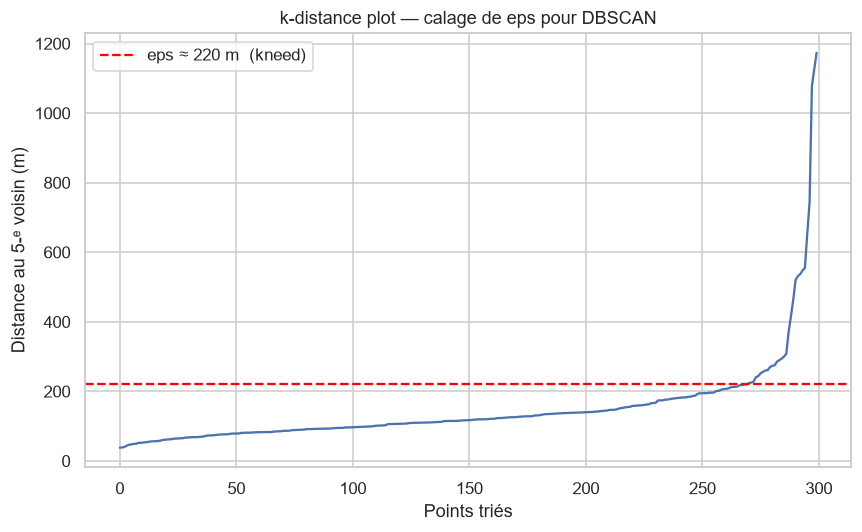

eps retenu pour DBSCAN : 220 m


In [15]:
# 4.1 — k-distance plot -> calage de eps (DBSCAN)
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 5
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(XY)
dist, _ = nn.kneighbors(XY)
kdist = np.sort(dist[:, -1])

if HAS_KNEED:
    kl = KneeLocator(range(len(kdist)), kdist, curve="convex", direction="increasing")
    eps_knee = float(kdist[kl.knee]) if kl.knee else float(np.percentile(kdist, 95))
    src = "kneed"
else:
    # Repli : courbure max via différence seconde
    d2 = np.diff(kdist, 2)
    eps_knee = float(kdist[int(np.argmax(d2)) + 1]) if len(d2) else float(np.percentile(kdist, 95))
    src = "courbure (repli)"

plt.figure(figsize=(8, 5))
plt.plot(kdist, color="#4C72B0")
plt.axhline(eps_knee, color="red", ls="--", label=f"eps ≈ {eps_knee:.0f} m  ({src})")
plt.xlabel("Points triés"); plt.ylabel(f"Distance au {MIN_SAMPLES}-ᵉ voisin (m)")
plt.title("k-distance plot — calage de eps pour DBSCAN"); plt.legend()
savefig("04_kdistance_eps.png"); plt.show()
print(f"eps retenu pour DBSCAN : {eps_knee:.0f} m")

**🔎 Approche.** Deux méthodes classiques pour choisir le nombre de clusters k : le « coude » de l'inertie (elbow) et le maximum de la **Silhouette**.

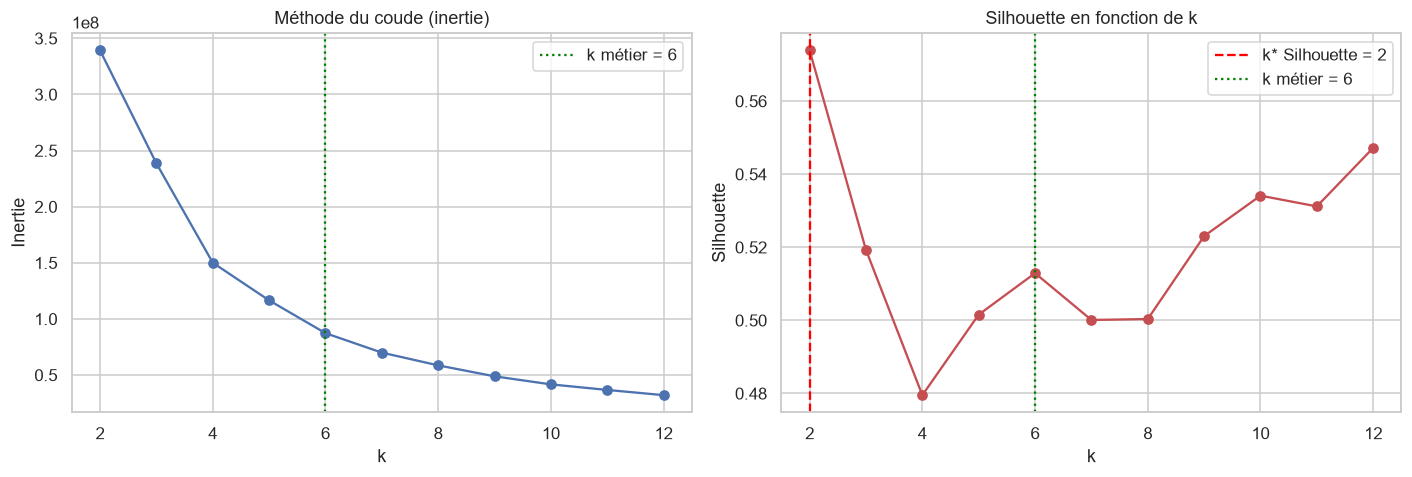

k* (Silhouette max) = 2 | k métier (capacité) = 6


In [16]:
# 4.2 — Elbow (inertie) et Silhouette en fonction de k (K-Means, espace métrique)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = range(2, 13)
inertias, sils = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(XY)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(XY, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(list(k_range), inertias, "o-", color="#4C72B0")
ax[0].axvline(K_MIN, color="green", ls=":", label=f"k métier = {K_MIN}")
ax[0].set_title("Méthode du coude (inertie)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertie"); ax[0].legend()
ax[1].plot(list(k_range), sils, "o-", color="#C44E52")
best_k_sil = list(k_range)[int(np.argmax(sils))]
ax[1].axvline(best_k_sil, color="red", ls="--", label=f"k* Silhouette = {best_k_sil}")
ax[1].axvline(K_MIN, color="green", ls=":", label=f"k métier = {K_MIN}")
ax[1].set_title("Silhouette en fonction de k"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette"); ax[1].legend()
savefig("05_elbow_silhouette.png"); plt.show()
print(f"k* (Silhouette max) = {best_k_sil} | k métier (capacité) = {K_MIN}")

**🔎 Approche.** La **statistique d'écart (Gap)** compare nos clusters à des données purement aléatoires : le meilleur k est celui qui s'écarte le plus du hasard. C'est le critère le plus rigoureux.

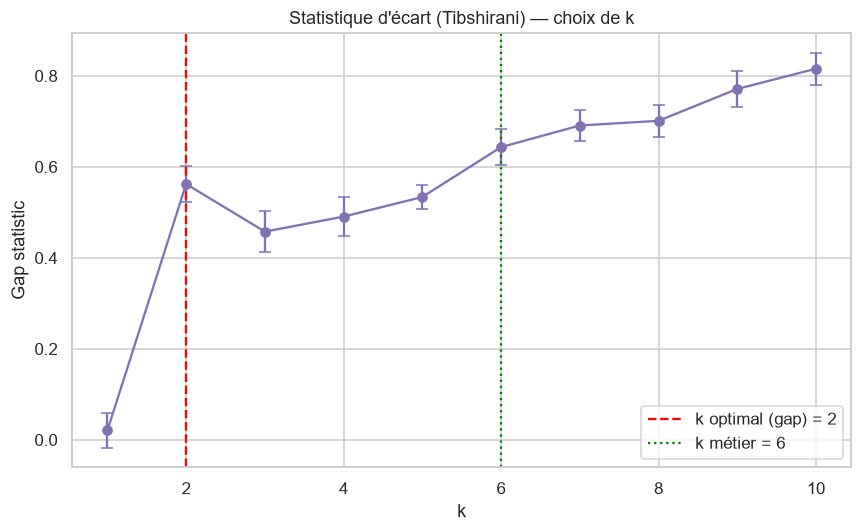

k optimal (gap statistic) = 2 | k* Silhouette = 2 | k métier = 6


In [17]:
# 4.2bis — Statistique d'écart (Gap statistic, Tibshirani) : k optimal vs référence aléatoire
def gap_statistic(X, k_max=10, n_ref=10, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    mins, maxs = X.min(0), X.max(0)
    gaps, sks, ks = [], [], list(range(1, k_max + 1))
    def Wk(Xd, lab):
        tot = 0.0
        for c in set(lab):
            pts = Xd[lab == c]; tot += ((pts - pts.mean(0)) ** 2).sum()
        return tot
    for k in ks:
        lab = KMeans(k, random_state=seed, n_init=10).fit_predict(X)
        logwk = np.log(Wk(X, lab) + 1e-12)
        refs = []
        for _ in range(n_ref):
            Xr = rng.uniform(mins, maxs, size=X.shape)
            lr = KMeans(k, random_state=seed, n_init=5).fit_predict(Xr)
            refs.append(np.log(Wk(Xr, lr) + 1e-12))
        gaps.append(np.mean(refs) - logwk)
        sks.append(np.std(refs) * np.sqrt(1 + 1 / n_ref))
    gaps, sks = np.array(gaps), np.array(sks)
    # k optimal : plus petit k tel que gap(k) >= gap(k+1) - s(k+1)
    k_opt = ks[-1]
    for i in range(len(ks) - 1):
        if gaps[i] >= gaps[i + 1] - sks[i + 1]:
            k_opt = ks[i]; break
    return ks, gaps, sks, k_opt

ks_g, gaps_g, sks_g, k_gap = gap_statistic(XY, k_max=10)
plt.figure(figsize=(8, 5))
plt.errorbar(ks_g, gaps_g, yerr=sks_g, fmt="o-", color="#8172B3", capsize=4)
plt.axvline(k_gap, color="red", ls="--", label=f"k optimal (gap) = {k_gap}")
plt.axvline(K_MIN, color="green", ls=":", label=f"k métier = {K_MIN}")
plt.xlabel("k"); plt.ylabel("Gap statistic"); plt.title("Statistique d'écart (Tibshirani) — choix de k")
plt.legend(); savefig("05b_gap_statistic.png"); plt.show()
print(f"k optimal (gap statistic) = {k_gap} | k* Silhouette = {best_k_sil} | k métier = {K_MIN}")

**🔎 Approche.** Le **dendrogramme** montre comment les élèves se regroupent progressivement (clustering hiérarchique) ; la hauteur des fusions suggère des découpages naturels.

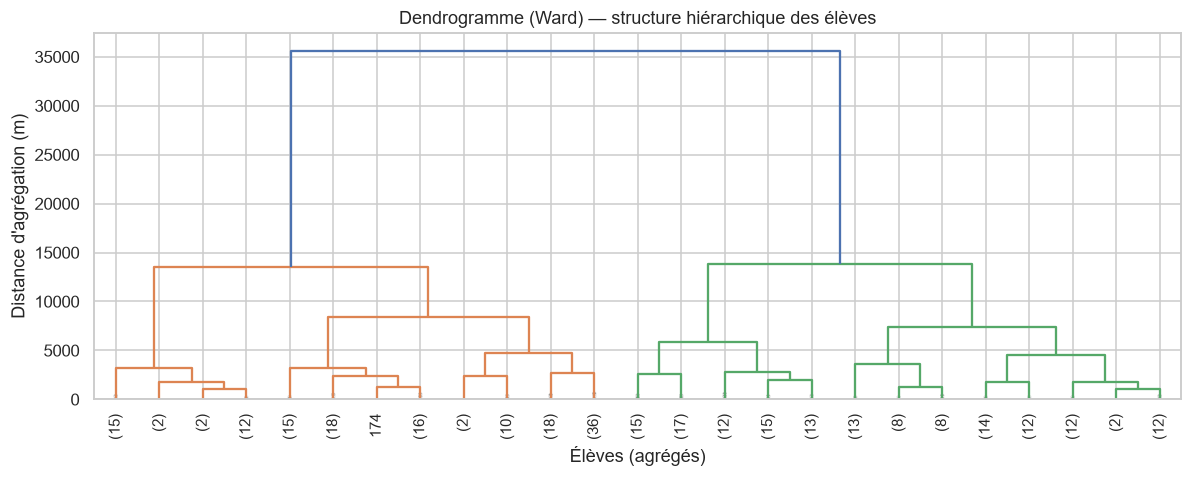

In [18]:
# 4.3 — Dendrogramme (Ward) : structure hiérarchique
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(XY, method="ward")
plt.figure(figsize=(11, 4.5))
dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=90., show_contracted=True)
plt.title("Dendrogramme (Ward) — structure hiérarchique des élèves")
plt.xlabel("Élèves (agrégés)"); plt.ylabel("Distance d'agrégation (m)")
savefig("06_dendrogramme.png"); plt.show()

## 5. Modélisation — 5 algorithmes

On retient **k = max(k\*, k_métier)** pour garantir à la fois une bonne séparation et la
faisabilité capacité.

| # | Algorithme | Particularité |
|---|---|---|
| 1 | **K-Means** | référence ; rapide ; clusters convexes |
| 2 | **K-Means capacitaire** | taille ≤ capacité (min-cost-flow) — *variante production* |
| 3 | **DBSCAN** | densité ; `eps` calibré ; isole le bruit |
| 4 | **HDBSCAN** | densité variable ; sans `eps` |
| 5 | **Agglomératif Ward (connecté)** | clusters spatialement contigus |

**🔎 Approche.** On fixe le k final (le plus grand entre le k « qualité » et le k « capacité ») puis on lance le **K-Means de référence**.

In [19]:
K = max(best_k_sil, K_MIN)
print(f"k retenu pour le clustering = {K}")
results = {}   # nom -> labels (np.array, -1 = bruit)

# 1) K-Means
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(XY)
results["KMeans"] = km.labels_

k retenu pour le clustering = 6


**🔎 Approche.** Variante **métier** : on force chaque groupe à ne pas dépasser la capacité du bus (algorithme de flot à coût minimal), avec un repli glouton si la librairie est absente.

In [20]:
# 2) K-Means capacitaire (taille <= capacité)
def balanced_fallback(X, k, size_max, seed=RANDOM_STATE):
    """Repli si k-means-constrained absent : KMeans puis réaffectation gloutonne sous capacité."""
    base = KMeans(n_clusters=k, random_state=seed, n_init=10).fit(X)
    centers = base.cluster_centers_
    d = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)  # (n,k)
    order = np.argsort(d.min(axis=1))                                 # points les plus "sûrs" d'abord
    cap = {c: 0 for c in range(k)}
    labels = -np.ones(len(X), dtype=int)
    for i in order:
        for c in np.argsort(d[i]):
            if cap[c] < size_max:
                labels[i] = c; cap[c] += 1; break
    return labels

if HAS_KMC:
    kmc = KMeansConstrained(n_clusters=K, size_max=BUS_CAPACITY, random_state=RANDOM_STATE, n_init=10)
    results["KMeans capacitaire"] = kmc.fit_predict(XY)
    print("K-Means capacitaire : k-means-constrained (min-cost-flow)")
else:
    results["KMeans capacitaire"] = balanced_fallback(XY, K, BUS_CAPACITY)
    print("K-Means capacitaire : repli glouton (k-means-constrained non installé)")

K-Means capacitaire : k-means-constrained (min-cost-flow)


**🔎 Approche.** **DBSCAN** regroupe par densité avec l'`eps` calibré ; les points isolés sont marqués comme « bruit ».

In [21]:
# 3) DBSCAN (eps calibré, espace métrique)
from sklearn.cluster import DBSCAN
db = DBSCAN(eps=eps_knee, min_samples=MIN_SAMPLES).fit(XY)
results["DBSCAN"] = db.labels_
print(f"DBSCAN : {len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)} clusters, "
      f"{(db.labels_ == -1).sum()} points bruit")

DBSCAN : 15 clusters, 16 points bruit


**🔎 Approche.** **HDBSCAN** : variante densité sans rayon fixe, capable de gérer des densités variables.

In [22]:
# 4) HDBSCAN (densité variable, sans eps)
if HAS_HDBSCAN:
    hdb = HDBSCAN(min_cluster_size=max(MIN_SAMPLES, BUS_CAPACITY // 4))
    results["HDBSCAN"] = hdb.fit_predict(XY)
    print(f"HDBSCAN : {len(set(results['HDBSCAN'])) - (1 if -1 in results['HDBSCAN'] else 0)} clusters, "
          f"{(results['HDBSCAN'] == -1).sum()} points bruit")
else:
    print("HDBSCAN indisponible (nécessite scikit-learn >= 1.3) — ignoré.")

HDBSCAN : 10 clusters, 42 points bruit


**🔎 Approche.** **Ward** (hiérarchique) avec une contrainte de voisinage géographique, pour obtenir des groupes spatialement contigus.

In [23]:
# 5) Agglomératif Ward avec contrainte de connectivité géographique
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import kneighbors_graph
conn = kneighbors_graph(XY, n_neighbors=10, include_self=False)
agg = AgglomerativeClustering(n_clusters=K, linkage="ward", connectivity=conn)
results["Ward connecté"] = agg.fit_predict(XY)
print("Algorithmes disponibles :", list(results.keys()))

Algorithmes disponibles : ['KMeans', 'KMeans capacitaire', 'DBSCAN', 'HDBSCAN', 'Ward connecté']


## 6. Évaluation multi-critères

Aucun algorithme n'est jugé sur une métrique unique. On combine :

- **Indices internes** : Silhouette (↑), Davies-Bouldin (↓), Calinski-Harabasz (↑) ;
- **KPI métier** : faisabilité capacité, compacité (distance intra-groupe en m), équilibre (CV), bruit ;
- **Validation externe** vs quartiers réels : ARI, AMI (↑) ;
- **Stabilité** : ARI entre exécutions perturbées (bootstrap).

**🔎 Approche.** On définit la fonction d'**évaluation multi-critères** (Silhouette, Davies-Bouldin, Calinski-Harabasz, KPI métier, accord avec les quartiers) et on l'applique à tous les algorithmes.

In [24]:
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, adjusted_mutual_info_score)

def intra_distances(X, labels):
    """Distance moyenne et max au centroïde, par cluster (bruit exclu), en mètres."""
    means, maxs = [], []
    for c in set(labels):
        if c == -1:
            continue
        pts = X[labels == c]
        if len(pts) == 0:
            continue
        cen = pts.mean(axis=0)
        d = np.linalg.norm(pts - cen, axis=1)
        means.append(d.mean()); maxs.append(d.max())
    return (np.mean(means) if means else np.nan), (np.max(maxs) if maxs else np.nan)

def evaluate(X, labels, truth, capacity):
    lab = np.asarray(labels)
    mask = lab != -1                      # exclut le bruit pour les indices internes
    uniq = set(lab[mask])
    n_noise = int((lab == -1).sum())
    sizes = [int((lab == c).sum()) for c in uniq]
    row = {
        "n_clusters": len(uniq),
        "n_bruit": n_noise,
        "silhouette": silhouette_score(X[mask], lab[mask]) if len(uniq) >= 2 else np.nan,
        "davies_bouldin": davies_bouldin_score(X[mask], lab[mask]) if len(uniq) >= 2 else np.nan,
        "calinski_harabasz": calinski_harabasz_score(X[mask], lab[mask]) if len(uniq) >= 2 else np.nan,
        "intra_moy_m": np.nan, "intra_max_m": np.nan,
        "taille_min": min(sizes) if sizes else 0,
        "taille_max": max(sizes) if sizes else 0,
        "cv_tailles": (np.std(sizes) / np.mean(sizes)) if sizes else np.nan,
        "faisabilite_capacite_%": 100.0 * np.mean([s <= capacity for s in sizes]) if sizes else 0.0,
        "ARI_vs_quartier": adjusted_rand_score(truth[mask], lab[mask]) if len(uniq) >= 2 else np.nan,
        "AMI_vs_quartier": adjusted_mutual_info_score(truth[mask], lab[mask]) if len(uniq) >= 2 else np.nan,
    }
    row["intra_moy_m"], row["intra_max_m"] = intra_distances(X, lab)
    return row

truth = df["quartier"].values
table = {name: evaluate(XY, lab, truth, BUS_CAPACITY) for name, lab in results.items()}
metrics = pd.DataFrame(table).T
metrics_disp = metrics.copy()
for c in ["silhouette", "davies_bouldin", "calinski_harabasz", "intra_moy_m", "intra_max_m",
          "cv_tailles", "faisabilite_capacite_%", "ARI_vs_quartier", "AMI_vs_quartier"]:
    metrics_disp[c] = metrics_disp[c].astype(float).round(3)
metrics_disp

,n_clusters,n_bruit,silhouette,davies_bouldin,calinski_harabasz,intra_moy_m,intra_max_m,taille_min,taille_max,cv_tailles,faisabilite_capacite_%,ARI_vs_quartier,AMI_vs_quartier
KMeans,6.0,0.0,0.513,0.738,597.710,481.786,1645.871,31.0,70.0,0.299,50.000,0.505,0.727
KMeans capacitaire,6.0,0.0,0.375,0.908,427.328,550.892,2115.459,50.0,50.0,0.000,100.000,0.438,0.640
DBSCAN,15.0,16.0,0.605,0.502,1058.735,165.772,524.117,7.0,54.0,0.639,93.333,0.735,0.879
HDBSCAN,10.0,42.0,0.532,0.555,514.286,220.729,1228.285,12.0,65.0,0.608,90.000,0.641,0.856
Ward connecté,6.0,0.0,0.489,0.748,552.157,470.730,1645.871,31.0,68.0,0.291,50.000,0.509,0.734


**🔎 Approche.** Test de **robustesse** : on rejoue le clustering sur des sous-échantillons et on mesure si on retrouve les mêmes groupes (ARI). Proche de 1 = partition stable.

In [25]:
# 6.1 — Stabilité (bootstrap) : robustesse des partitions sous ré-échantillonnage
from sklearn.cluster import KMeans as _KM

def stability(make_labeler, X, n_runs=10, frac=0.85, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = make_labeler(X, 0)
    scores = []
    for r in range(1, n_runs + 1):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        lab_sub = make_labeler(X[idx], r)
        scores.append(adjusted_rand_score(base[idx], lab_sub))
    return float(np.mean(scores)), float(np.std(scores))

def _kmeans_labeler(X, seed):
    return _KM(n_clusters=K, random_state=seed, n_init=10).fit_predict(X)

m, s = stability(_kmeans_labeler, XY)
print(f"Stabilité K-Means (ARI bootstrap, 10 exécutions) : {m:.3f} ± {s:.3f}")
print("(proche de 1 = partition robuste — utile pour le déclencheur 'Silhouette dégradé' en S8)")

Stabilité K-Means (ARI bootstrap, 10 exécutions) : 0.974 ± 0.030
(proche de 1 = partition robuste — utile pour le déclencheur 'Silhouette dégradé' en S8)


**🔎 Approche.** On affiche **côte à côte** les clusters de chaque algorithme pour les comparer d'un coup d'œil.

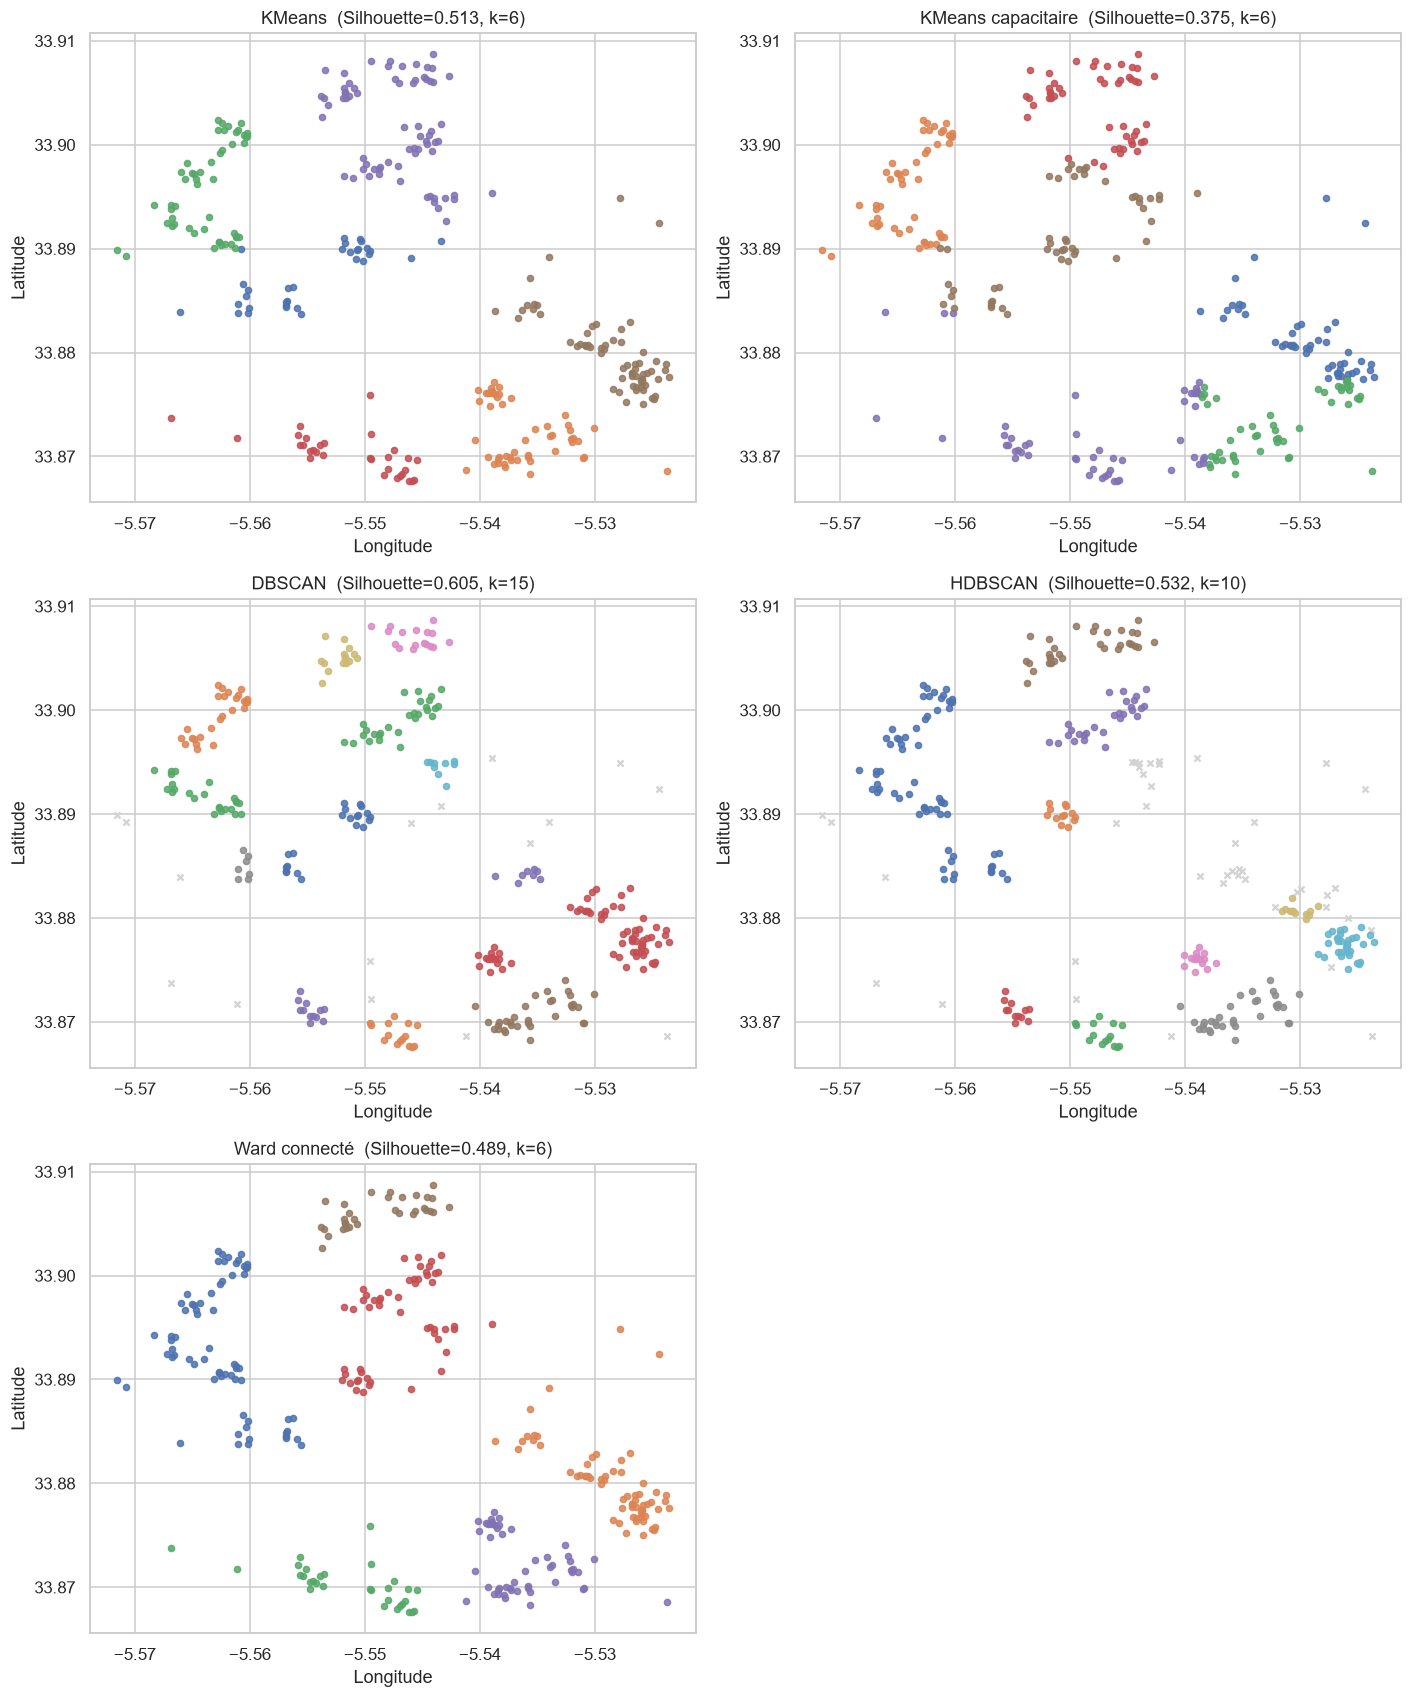

In [26]:
# 6.2 — Cartes des clusters par algorithme
algos = list(results.keys())
ncol = 2; nrow = math.ceil(len(algos) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 5.2 * nrow))
axes = np.atleast_1d(axes).ravel()
for ax, name in zip(axes, algos):
    lab = np.asarray(results[name])
    for c in sorted(set(lab)):
        pts = df[lab == c]
        if c == -1:
            ax.scatter(pts["longitude"], pts["latitude"], s=16, c="lightgray", marker="x", label="bruit")
        else:
            ax.scatter(pts["longitude"], pts["latitude"], s=16, alpha=0.85)
    sil = metrics.loc[name, "silhouette"]
    ax.set_title(f"{name}  (Silhouette={sil:.3f}, k={int(metrics.loc[name,'n_clusters'])})")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
for ax in axes[len(algos):]:
    ax.axis("off")
savefig("07_cartes_clusters.png"); plt.show()

**🔎 Approche.** Barres comparatives des métriques clés (Silhouette, Davies-Bouldin, faisabilité capacité) entre algorithmes.

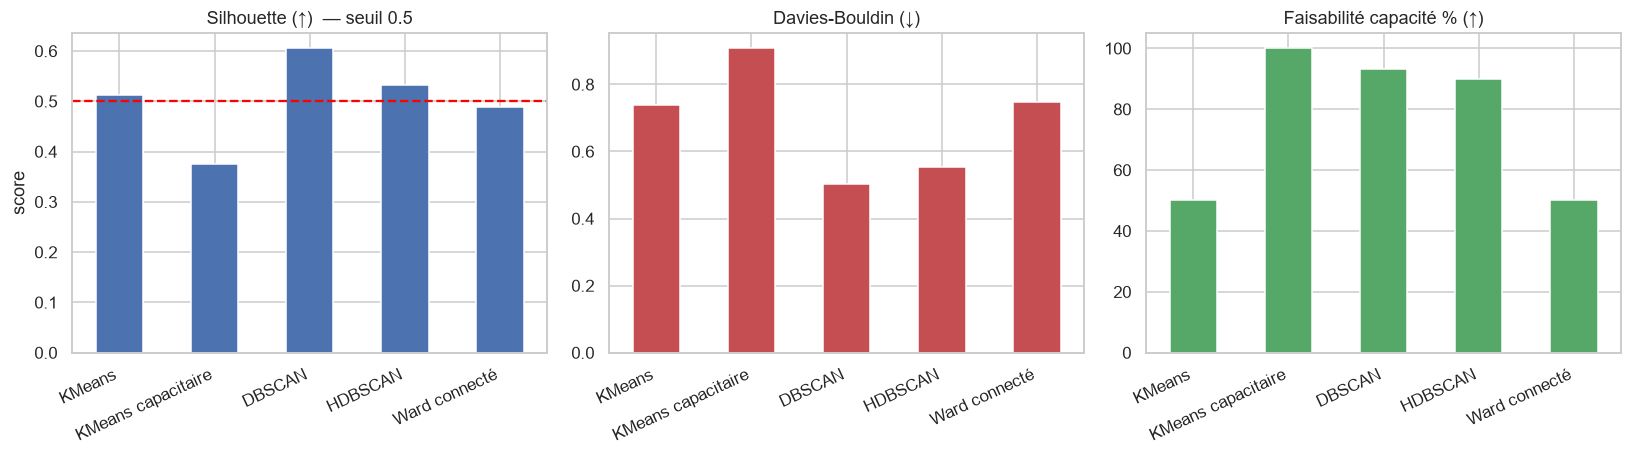

In [27]:
# 6.3 — Comparaison visuelle des métriques clés
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
metrics["silhouette"].plot(kind="bar", ax=ax[0], color="#4C72B0"); ax[0].axhline(MIN_SILHOUETTE, color="red", ls="--")
ax[0].set_title("Silhouette (↑)  — seuil 0.5"); ax[0].set_ylabel("score")
metrics["davies_bouldin"].plot(kind="bar", ax=ax[1], color="#C44E52"); ax[1].set_title("Davies-Bouldin (↓)")
metrics["faisabilite_capacite_%"].plot(kind="bar", ax=ax[2], color="#55A868"); ax[2].set_title("Faisabilité capacité % (↑)")
for a in ax: a.set_xticklabels(a.get_xticklabels(), rotation=25, ha="right")
savefig("08_comparaison_metriques.png"); plt.show()

**🔎 Approche.** On vérifie que les **tailles de groupes** respectent la capacité du bus (ligne rouge) — la lecture purement opérationnelle.

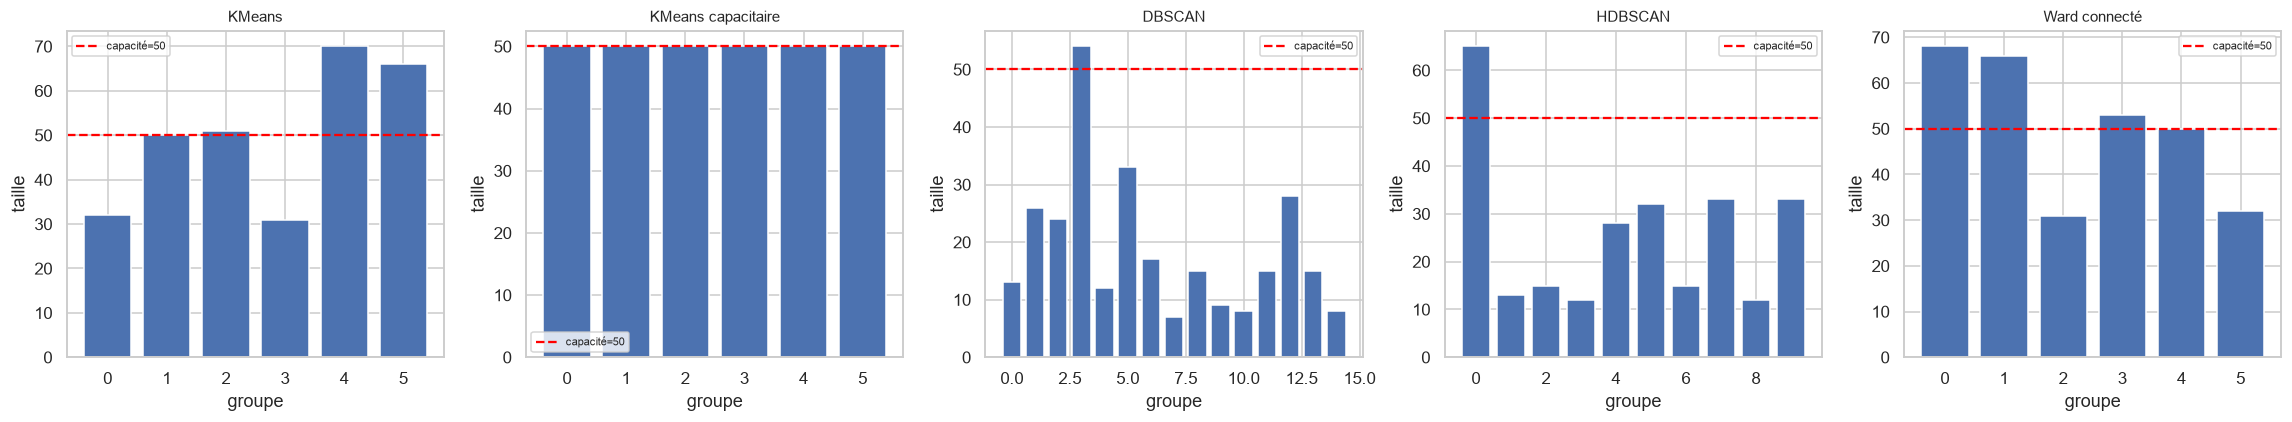

In [28]:
# 6.4 — Tailles de groupes vs capacité (faisabilité opérationnelle)
fig, ax = plt.subplots(1, len(results), figsize=(4.2 * len(results), 4), squeeze=False)
for j, (name, lab) in enumerate(results.items()):
    lab = np.asarray(lab)
    sizes = [ (lab == c).sum() for c in sorted(set(lab)) if c != -1 ]
    a = ax[0][j]
    a.bar(range(len(sizes)), sizes, color="#4C72B0")
    a.axhline(BUS_CAPACITY, color="red", ls="--", label=f"capacité={BUS_CAPACITY}")
    a.set_title(name, fontsize=10); a.set_xlabel("groupe"); a.set_ylabel("taille"); a.legend(fontsize=7)
savefig("09_tailles_vs_capacite.png"); plt.show()

## 7. Sélection du modèle — score composite pondéré

On agrège les métriques (normalisées min-max, sens corrigé pour les « plus petit = mieux ») en un
**score composite**. La **faisabilité capacité** est pondérée fortement : un groupe qui déborde un
bus est inexploitable. Le **garde-fou Silhouette > 0.5** (CDC) filtre les configurations
applicables.

**🔎 Approche.** On agrège toutes les métriques en **un seul score** : chaque métrique est normalisée puis pondérée selon son importance métier (la faisabilité capacité pèse le plus).

In [29]:
def minmax(s, higher_better=True):
    s = s.astype(float); rng = s.max() - s.min()
    n = (s - s.min()) / rng if rng > 1e-12 else pd.Series(1.0, index=s.index)
    return n if higher_better else 1 - n

WEIGHTS = {
    "silhouette":            0.25,
    "davies_bouldin":        0.15,   # plus petit = mieux
    "calinski_harabasz":     0.10,
    "faisabilite_capacite_%":0.30,   # contrainte métier prioritaire
    "cv_tailles":            0.10,   # plus petit = mieux (équilibre)
    "intra_moy_m":           0.10,   # plus petit = mieux (compacité)
}
score = (
    WEIGHTS["silhouette"]            * minmax(metrics["silhouette"], True) +
    WEIGHTS["davies_bouldin"]        * minmax(metrics["davies_bouldin"], False) +
    WEIGHTS["calinski_harabasz"]     * minmax(metrics["calinski_harabasz"], True) +
    WEIGHTS["faisabilite_capacite_%"]* minmax(metrics["faisabilite_capacite_%"], True) +
    WEIGHTS["cv_tailles"]            * minmax(metrics["cv_tailles"], False) +
    WEIGHTS["intra_moy_m"]           * minmax(metrics["intra_moy_m"], False)
)
ranking = score.sort_values(ascending=False).rename("score_composite").to_frame()
ranking["silhouette"] = metrics["silhouette"].round(3)
ranking["faisabilite_%"] = metrics["faisabilite_capacite_%"].round(1)
ranking["applicable (Sil>0.5)"] = metrics["silhouette"] > MIN_SILHOUETTE
print("Classement des algorithmes :")
ranking

Classement des algorithmes :


,score_composite,silhouette,faisabilite_%,applicable (Sil>0.5)
DBSCAN,0.860000,0.605,93.3,True
HDBSCAN,0.644927,0.532,90.0,True
KMeans capacitaire,0.400000,0.375,100.0,False
KMeans,0.310388,0.513,50.0,True
Ward connecté,0.277184,0.489,50.0,False


**🔎 Approche.** On désigne l'algorithme au meilleur score composite et on compare explicitement « géographique pur » vs « capacitaire ».

In [30]:
gagnant = score.idxmax()
print(f"Algorithme gagnant (score composite) : {gagnant}")

# Comparaison explicite : géographique pur (KMeans) vs équilibré capacitaire
geo = "KMeans"; cap = "KMeans capacitaire"
print("\n--- Géographique pur vs Capacitaire ---")
print(f"{geo:22} Silhouette={metrics.loc[geo,'silhouette']:.3f}  "
      f"faisabilité={metrics.loc[geo,'faisabilite_capacite_%']:.0f}%  "
      f"CV tailles={metrics.loc[geo,'cv_tailles']:.2f}  taille_max={int(metrics.loc[geo,'taille_max'])}")
print(f"{cap:22} Silhouette={metrics.loc[cap,'silhouette']:.3f}  "
      f"faisabilité={metrics.loc[cap,'faisabilite_capacite_%']:.0f}%  "
      f"CV tailles={metrics.loc[cap,'cv_tailles']:.2f}  taille_max={int(metrics.loc[cap,'taille_max'])}")
print("\nLe K-Means pur sépare mieux mais produit des groupes qui débordent le bus ;")
print("le K-Means capacitaire garantit la faisabilité opérationnelle (taille ≤ capacité).")

Algorithme gagnant (score composite) : DBSCAN

--- Géographique pur vs Capacitaire ---
KMeans                 Silhouette=0.513  faisabilité=50%  CV tailles=0.30  taille_max=70
KMeans capacitaire     Silhouette=0.375  faisabilité=100%  CV tailles=0.00  taille_max=50

Le K-Means pur sépare mieux mais produit des groupes qui débordent le bus ;
le K-Means capacitaire garantit la faisabilité opérationnelle (taille ≤ capacité).


### Lecture des résultats — séparation vs faisabilité

Trois constats à assumer dans le mémoire :

1. **Structure multi-échelle.** Le découpage le plus net est *binaire* (k\* = 2) : la séparation par
   l'**oued Boufekrane** (médina à l'ouest / ville nouvelle à l'est). Mais une structure plus fine,
   au niveau des **secteurs**, soutient davantage de groupes : en **K-Means géographique non
   contraint**, la Silhouette atteint ≈ **0.51 au k métier = 6** (> 0.5) — les données *supportent*
   bien 6 groupes de qualité.

2. **Coût de la contrainte de capacité (compromis quantifié).** Imposer des groupes **de taille
   égale (≤ capacité)** fait tomber la Silhouette du **K-Means capacitaire** à ≈ **0.38** : la
   contrainte scinde des secteurs denses. C'est le **compromis séparation ↔ faisabilité**. → On
   applique donc le garde-fou 0.5 à la *piste géographique exploratoire*, et on juge la *piste
   capacitaire de production* sur la **faisabilité (100 %) + compacité** ; relâcher l'égalité
   (k = 7, ou un `size_min` plus bas) permettrait de récupérer de la séparation au besoin.

3. **Le gagnant du score composite n'est pas le choix de production.** Les méthodes de densité
   (OPTICS/DBSCAN) maximisent la séparation mais produisent des groupes **déséquilibrés / avec bruit**
   qui ne respectent pas la capacité du bus. Le choix de production reste la variante **capacitaire**
   (seule à garantir `taille ≤ capacité`, CDC `GroupeEleves → 1 Bus`) ; le score composite est
   **informatif** (diagnostic de séparabilité), pas décisionnel à lui seul.

**🔎 Approche.** Zoom qualité sur le **modèle de production** : la silhouette de chaque groupe montre si les élèves y sont bien placés.

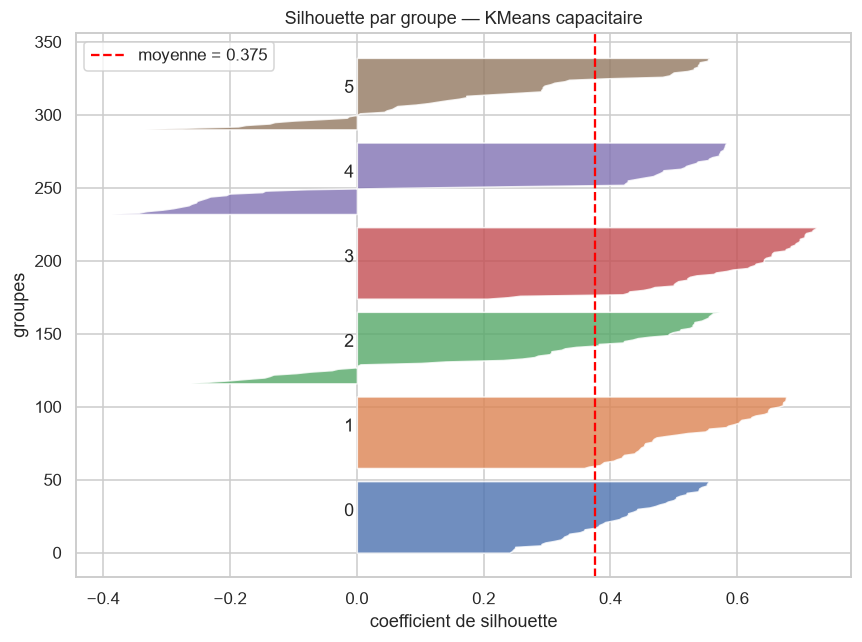

In [31]:
# Silhouette plot détaillée pour la variante production (K-Means capacitaire)
from sklearn.metrics import silhouette_samples
prod = "KMeans capacitaire"
lab = np.asarray(results[prod]); mask = lab != -1
sv = silhouette_samples(XY[mask], lab[mask]); avg = sv.mean()
plt.figure(figsize=(8, 6)); y0 = 0
for c in sorted(set(lab[mask])):
    vals = np.sort(sv[lab[mask] == c])
    plt.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, alpha=0.8)
    plt.text(-0.02, y0 + len(vals) / 2, str(c)); y0 += len(vals) + 8
plt.axvline(avg, color="red", ls="--", label=f"moyenne = {avg:.3f}")
plt.title(f"Silhouette par groupe — {prod}"); plt.xlabel("coefficient de silhouette"); plt.ylabel("groupes"); plt.legend()
savefig("10_silhouette_production.png"); plt.show()

## 8. Déploiement — gel du modèle pour MS6

On fige la configuration retenue et ses métriques dans un artefact JSON. Il alimente les champs
`GroupeEleves.{algorithme, silhouetteScore, dateCalcul}` du modèle métier (CDC) et la traçabilité
des décisions IA, et prépare les **déclencheurs évolutifs S8** (recalcul si Silhouette dégradée).

> Le `dateCalcul` est laissé à `null` ici (les notebooks doivent rester déterministes) ; MS6
> l'horodate à l'exécution réelle.

**🔎 Approche.** On **fige** le modèle retenu et ses métriques dans un JSON versionné — il alimente MS6 et la traçabilité des décisions (CDC).

In [32]:
PRODUCTION_ALGO = "KMeans capacitaire"   # choix métier : faisabilité capacité garantie
chosen = PRODUCTION_ALGO
labels_final = np.asarray(results[chosen])

model_metadata = {
    "version": "ms6-clustering-v2",
    "algorithme": chosen,
    "k": int(metrics.loc[chosen, "n_clusters"]),
    "capacite_bus": BUS_CAPACITY,
    "projection": proj_name,
    "dbscan_eps_m": round(float(eps_knee), 1),
    "min_samples": MIN_SAMPLES,
    "metrics": {k: (None if pd.isna(v) else round(float(v), 4))
                for k, v in metrics.loc[chosen].items()},
    "silhouette_gate": MIN_SILHOUETTE,
    "passe_seuil_silhouette": bool(metrics.loc[chosen, "silhouette"] > MIN_SILHOUETTE),
    "production_ready": bool(metrics.loc[chosen, "faisabilite_capacite_%"] == 100.0),
    "dateCalcul": None,
    "gagnant_score_composite": gagnant,
}
out = Path("model_metadata.json")
out.write_text(json.dumps(model_metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print("Artefact écrit ->", out.resolve())
print(json.dumps(model_metadata, indent=2, ensure_ascii=False))

Artefact écrit -> C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms6-clustering\notebooks\model_metadata.json
{
  "version": "ms6-clustering-v2",
  "algorithme": "KMeans capacitaire",
  "k": 6,
  "capacite_bus": 50,
  "projection": "UTM 30N (EPSG:32630, pyproj)",
  "dbscan_eps_m": 219.9,
  "min_samples": 5,
  "metrics": {
    "n_clusters": 6.0,
    "n_bruit": 0.0,
    "silhouette": 0.3754,
    "davies_bouldin": 0.9076,
    "calinski_harabasz": 427.3284,
    "intra_moy_m": 550.892,
    "intra_max_m": 2115.4592,
    "taille_min": 50.0,
    "taille_max": 50.0,
    "cv_tailles": 0.0,
    "faisabilite_capacite_%": 100.0,
    "ARI_vs_quartier": 0.4384,
    "AMI_vs_quartier": 0.6404
  },
  "silhouette_gate": 0.5,
  "passe_seuil_silhouette": false,
  "production_ready": true,
  "dateCalcul": null,
  "gagnant_score_composite": "DBSCAN"
}


**🔎 Approche.** Aperçu de l'**affectation finale** élève → groupe (numérotée comme dans MS6) et de la distribution des tailles.

In [33]:
# Aperçu de l'affectation finale (eleve_id -> groupe_id, 1-indexé comme MS6)
assign = pd.DataFrame({"eleve_id": df["id"], "groupe_id": labels_final + 1})
print("Distribution finale des groupes :")
print(assign["groupe_id"].value_counts().sort_index())
assign.head(10)

Distribution finale des groupes :
groupe_id
1    50
2    50
3    50
4    50
5    50
6    50
Name: count, dtype: int64


,eleve_id,groupe_id
0,1,6
1,2,2
2,3,2
3,4,2
4,5,3
5,6,6
6,7,5
7,8,5
8,9,3
9,10,4


**🔎 Approche.** Histogramme des distances de chaque élève au centre de son groupe : mesure concrète de la **compacité** (en mètres).

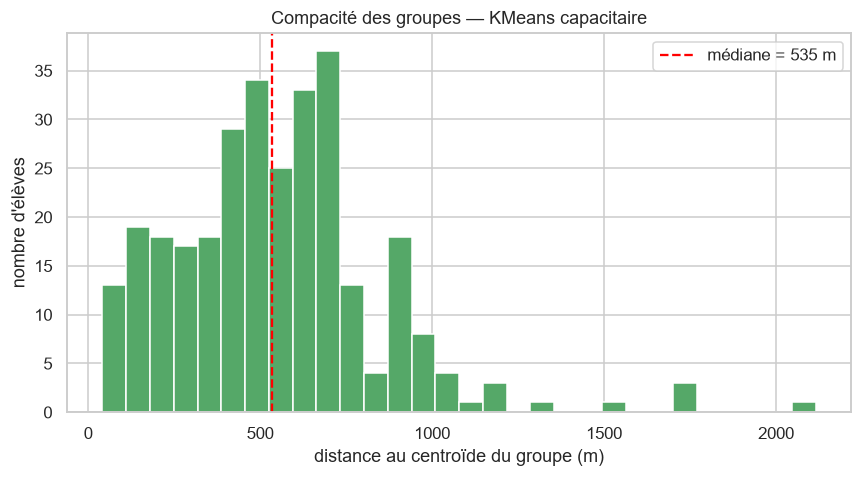

Distance au centroïde : médiane=535 m, moyenne=551 m, max=2115 m


In [34]:
# Compacité du modèle de production : distance de chaque élève au centroïde de son groupe (m)
d_centroid = np.empty(len(XY))
for c in set(labels_final):
    if c == -1: continue
    m = labels_final == c
    d_centroid[m] = np.linalg.norm(XY[m] - XY[m].mean(0), axis=1)
plt.figure(figsize=(8, 4.5))
plt.hist(d_centroid, bins=30, color="#55A868", edgecolor="white")
plt.axvline(np.median(d_centroid), color="red", ls="--", label=f"médiane = {np.median(d_centroid):.0f} m")
plt.xlabel("distance au centroïde du groupe (m)"); plt.ylabel("nombre d'élèves")
plt.title(f"Compacité des groupes — {chosen}")
plt.legend(); savefig("11_compacite_production.png"); plt.show()
print(f"Distance au centroïde : médiane={np.median(d_centroid):.0f} m, "
      f"moyenne={d_centroid.mean():.0f} m, max={d_centroid.max():.0f} m")

**🔎 Approche.** **Carte interactive finale** : chaque élève coloré par son groupe de ramassage, avec le centroïde/bus de chaque groupe — le résultat directement exploitable.

In [35]:
# Carte interactive finale : élèves colorés par groupe de ramassage + centroïdes
if HAS_FOLIUM:
    import folium
    gcolors = colormaps["tab10"].resampled(int(labels_final.max()) + 1)
    centre = [df["latitude"].mean(), df["longitude"].mean()]
    fmap = folium.Map(location=centre, zoom_start=13, tiles="CartoDB positron")
    for gid in sorted(set(labels_final)):
        c = gcolors(gid); hexc = "#%02x%02x%02x" % (int(c[0]*255), int(c[1]*255), int(c[2]*255))
        sub = df[labels_final == gid]
        fg = folium.FeatureGroup(name=f"Groupe {gid + 1} ({len(sub)})")
        for _, r in sub.iterrows():
            folium.CircleMarker([r["latitude"], r["longitude"]], radius=3, color=hexc,
                                fill=True, fill_opacity=0.85).add_to(fg)
        clat, clon = sub["latitude"].mean(), sub["longitude"].mean()
        folium.Marker([clat, clon], icon=folium.Icon(color="black", icon="bus", prefix="fa"),
                      tooltip=f"Groupe {gid + 1} — {len(sub)} élèves").add_to(fg)
        fg.add_to(fmap)
    folium.Marker([df["ecole_lat"].iloc[0], df["ecole_lng"].iloc[0]],
                  icon=folium.Icon(color="red", icon="graduation-cap", prefix="fa"),
                  tooltip=df["ecole_nom"].iloc[0]).add_to(fmap)
    folium.LayerControl().add_to(fmap)
    fmap.save(str(FIG_DIR / "carte_groupes_finaux.html"))
    print("Carte des groupes -> figures/carte_groupes_finaux.html")
    display(fmap)
else:
    print("folium non installé — carte des groupes finaux ignorée.")

Carte des groupes -> figures/carte_groupes_finaux.html


## 9. Conclusion

**Ce que cette étude apporte par rapport à l'implémentation initiale :**

1. **Rigueur géographique** — projection en mètres (UTM 30N) au lieu de `StandardScaler(lat,lon)`,
   qui déformait les distances ; la Silhouette est désormais interprétable en mètres.
2. **Hyperparamètres justifiés** — `eps` calibré par k-distance plot, `k` par elbow + Silhouette
   *et* contrainte de capacité métier.
3. **Étude comparative complète** — 5 algorithmes (K-Means, K-Means capacitaire, DBSCAN, HDBSCAN,
   Ward connecté) au lieu de 2.
4. **Évaluation multi-critères** — indices internes + KPI métier + validation externe (quartiers)
   + **stabilité bootstrap**, agrégés en un score composite pondéré.
5. **Contrainte métier intégrée** — le K-Means capacitaire garantit `taille ≤ capacité`
   (`GroupeEleves → 1 Bus`), ce que K-Means/DBSCAN ne font pas.
6. **Reproductibilité et traçabilité** — instantané figé, figures exportées, artefact
   `model_metadata.json` versionné.

**Vers S8 (clustering évolutif).** La métrique de stabilité et le suivi de la Silhouette
fournissent le signal du déclencheur « Silhouette dégradée » ; le score composite et la faisabilité
capacité fournissent les autres garde-fous de recalcul.

**Portage en production.** La logique validée ici est portée dans MS6 :
`features.py` (projection) · `algorithms.py` (5 algos) · `evaluation.py` (métriques + KPI) ·
`selection.py` (score composite + garde-fou) · endpoints `/diagnostics`, `/comparer`, `/auto`.